# Sequential Neural Network for steel calssification with Augmented Data


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from keras.models import Sequential
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

## 1. Augmented Data from WGAN

In [2]:
# downsample St 48
original_data = pd.read_csv("../../labeled_OES_data_2.csv")
original_data_copy = original_data.copy()
deleting_number = 300
print(original_data.shape)
for index, row in original_data.iterrows():
    if row.iloc[-1] == "St 48" and deleting_number > 0:
        original_data.drop(index, inplace=True)
        deleting_number -= 1
print(original_data.shape)

(1429, 10)
(1129, 10)


In [3]:
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
st37_data = pd.read_csv("WGAN_Augmented_St37_NN.csv")
st48_TH_data = pd.read_csv("WGAN_Augmented_St48_TH_NN.csv")

st37_data["steel_class"] = "St 37"
st48_TH_data["steel_class"] = "St 48-TH"


data = pd.concat([original_data, st37_data, st48_TH_data])

data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.shape

(1298, 10)

In [4]:
X = data.iloc[:, :-1].astype(float).values
y = data.iloc[:, -1].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(len(y_test))

260


In [5]:
model = Sequential()
model.add(Dense(248, activation='relu', input_dim=data.shape[1] - 1))
model.add(Dense(124, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.05)))

model.add(Dense(32, activation='relu'))

model.add(Dense(len(label_encoder.classes_), activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


model.fit(X_train, y_train, epochs=800, batch_size=8, validation_data=(X_test, y_test))
print(len(y_test))

Epoch 1/800


C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


130/130 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3823 - loss: 4.1299 - val_accuracy: 0.7577 - val_loss: 1.4370
Epoch 2/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7567 - loss: 1.1541 - val_accuracy: 0.8577 - val_loss: 0.5687
Epoch 3/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8481 - loss: 0.6068 - val_accuracy: 0.8692 - val_loss: 0.4534
Epoch 4/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8752 - loss: 0.4680 - val_accuracy: 0.8923 - val_loss: 0.4059
Epoch 5/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8790 - loss: 0.4434 - val_accuracy: 0.9115 - val_loss: 0.3931
Epoch 6/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8936 - loss: 0.3945 - val_accuracy: 0.9038 - val_loss: 0.3737
Epoch 7/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8944 - loss: 0.4036 - val_accuracy: 0.9154 - val_loss: 0.3377
Epoch 8/800
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8989 - loss: 0.3838 - val_accuracy: 0.9038

In [6]:
predictions = model.predict(X_test)
predicted_classes = predictions.argmax(axis=-1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [7]:
previously_misclassified = [
    [0.22325, 0.005, 0.55975, 0.055075, 0.03135, 0.005, 0.0218, 0.009025, 0.033425, 1],
    [0.30916667, 0.00923333, 0.43033333, 0.03055, 0.02848333, 0.005, 0.02941667, 0.002, 0.05901667, 0],
    [0.18566667, 0.005, 0.4415, 0.01565, 0.03523333, 0.01906667, 0.0715, 0.002, 0.15033333, 1],
    [0.18333333, 0.1315, 0.55466667, 0.014, 0.03421667, 0.00855, 0.03136667, 0.02598333, 0.10983333, 1],
    [0.108, 0.0097, 0.565, 0.0254, 0.0262, 0.0214, 0.0431, 0.002, 0.121, 3],
    [0.22, 0.005, 0.57466667, 0.05326667, 0.03406667, 0.005, 0.02433333, 0.00851667, 0.03416667, 1],
    [0.0918, 0.005, 0.296, 0.0245, 0.0176, 0.0104, 0.0337, 0.002, 0.242, 3],
    [0.164, 0.12, 0.495, 0.0084, 0.0474, 0.005, 0.0452, 0.0192, 0.112, 1],
    [0.22885714, 0.005, 0.66557143, 0.03628571, 0.02588571, 0.06801429, 0.07972857, 0.03488571, 0.102, 0],
    [0.104, 0.005, 0.318, 0.0271, 0.0252, 0.0118, 0.0322, 0.0045, 0.261, 3],
    [0.1717, 0.1294, 0.6271, 0.0278, 0.0296, 0.0146, 0.0376, 0.0231, 0.1068, 1]
]
previously_misclassified = pd.DataFrame(previously_misclassified)

# make data numeric
#for column in previously_misclassified.columns:
#        for index, value in previously_misclassified[column].items():
#            if isinstance(value, str):
#                previously_misclassified.at[index, column] = value.replace(",", ".")

#previously_misclassified.loc[:, "steel_class"] = [classes_dict[c] for c in previously_misclassified["steel_class"] ]    

#previously_misclassified = previously_misclassified.map(pd.to_numeric)
#previously_misclassified.head()

In [8]:
previous_label = previously_misclassified.iloc[:, -1]
previously_misclassified_unlabeled = previously_misclassified.iloc[:, :-1]

In [9]:
n_prediction = (model.predict(previously_misclassified_unlabeled)).argmax(axis=-1)
correct = 0
for i in range(len(n_prediction)):
    print("Prediction: ", n_prediction[i], " - ", "GT: ", previous_label.iloc[i])
    if n_prediction[i] == previous_label.iloc[i]:
        correct += 1
print("In total correct: ", correct)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Prediction:  3  -  GT:  1
Prediction:  3  -  GT:  0
Prediction:  1  -  GT:  1
Prediction:  1  -  GT:  1
Prediction:  3  -  GT:  3
Prediction:  3  -  GT:  1
Prediction:  3  -  GT:  3
Prediction:  1  -  GT:  1
Prediction:  3  -  GT:  0
Prediction:  3  -  GT:  3
Prediction:  1  -  GT:  1
In total correct:  7


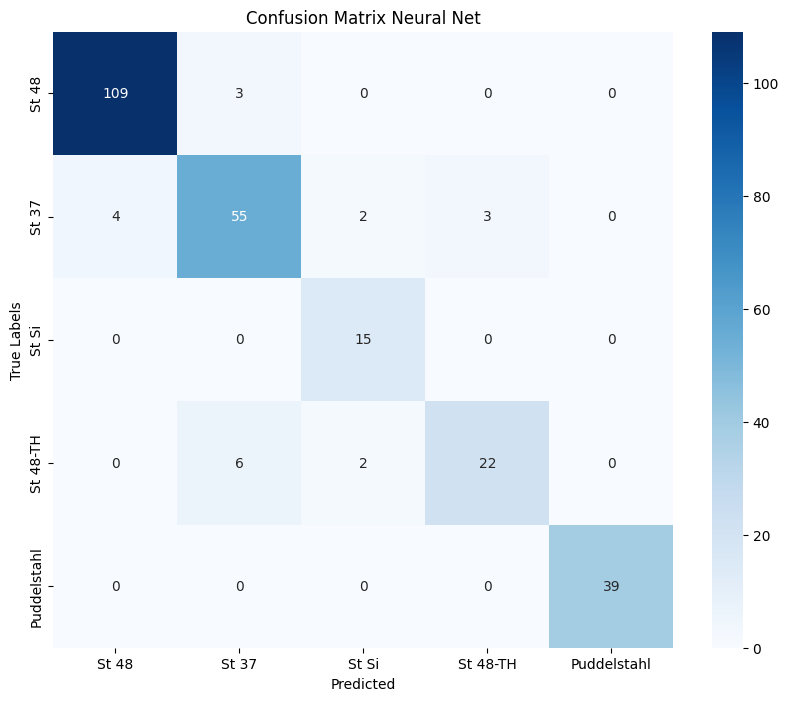

In [10]:
conf_matrix = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True Labels')
plt.title('Confusion Matrix Neural Net')
#plt.savefig('Confusion_Matrix_NN_Augmented.jpg', format='jpg')
plt.show()

In [27]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]

report = classification_report(y_test, predicted_classes, target_names=new_labels)
print(report)

              precision    recall  f1-score   support

       St 48       1.00      1.00      1.00       155
       St 37       1.00      0.99      1.00       112
       St Si       1.00      1.00      1.00       133
    St 48-TH       0.99      1.00      1.00       100
 Puddelstahl       1.00      1.00      1.00       131

    accuracy                           1.00       631
   macro avg       1.00      1.00      1.00       631
weighted avg       1.00      1.00      1.00       631



## 2. Augmented Data from SMOTE-ENN

In [19]:
data = pd.read_csv("resampled_steel_data.csv")
data.head()

,C,Si,Mn,P,S,Cr,Ni,Al,Cu,steel_class
0,0.212333,0.148667,0.710167,0.025033,0.051967,0.066517,0.068783,0.002000,0.189833,0
1,0.173000,0.511833,1.020000,0.021300,0.037750,0.341333,0.099983,0.054183,0.407667,0
2,0.291000,0.231000,0.665000,0.023000,0.042000,0.006000,0.051000,0.002000,0.188000,0
3,0.210000,0.268667,0.547333,0.016300,0.037067,0.044467,0.067700,0.002000,0.133333,0
4,0.211333,0.309833,0.659333,0.021533,0.042283,0.032600,0.121000,0.002700,0.211333,0


In [20]:
X = data.iloc[:, :-1].astype(float).values
y = data.iloc[:, -1].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

In [29]:
org_data = pd.read_csv("../../labeled_OES_data_2.csv")

# make data numeric

classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
org_data["steel_class"] = [classes_dict[c] for c in org_data["steel_class"] ]

for column in org_data.columns:
        for index, value in org_data[column].items():
            if isinstance(value, str):
                org_data.at[index, column] = value.replace(",", ".")
org_data = org_data.map(pd.to_numeric)

X_org = org_data.iloc[:,:-1]
y_org = org_data.iloc[:,-1]

X_train_org, X_test_org, y_train_org, y_test_org = train_test_split(X_org, y_org, test_size=0.2, random_state=42)

In [30]:
model_SMOTE_ENN = Sequential()
model_SMOTE_ENN.add(Dense(248, activation='relu', input_dim=data.shape[1] - 1))
model_SMOTE_ENN.add(Dense(124, activation='relu'))
model_SMOTE_ENN.add(Dropout(0.5))

model_SMOTE_ENN.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.05)))

model_SMOTE_ENN.add(Dense(32, activation='relu'))

model_SMOTE_ENN.add(Dense(len(label_encoder.classes_), activation='softmax'))

model_SMOTE_ENN.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


model_SMOTE_ENN.fit(X, y, epochs=800, batch_size=8, validation_data=(X_test_org, y_test_org))
print(len(y_test_org))

Epoch 1/800


C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5422 - loss: 2.6653 - val_accuracy: 0.9441 - val_loss: 0.3338
Epoch 2/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9377 - loss: 0.2991 - val_accuracy: 0.9371 - val_loss: 0.2697
Epoch 3/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9526 - loss: 0.2196 - val_accuracy: 0.9091 - val_loss: 0.3852
Epoch 4/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9602 - loss: 0.1825 - val_accuracy: 0.9266 - val_loss: 0.2906
Epoch 5/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9654 - loss: 0.1571 - val_accuracy: 0.9056 - val_loss: 0.4216
Epoch 6/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9630 - loss: 0.1551 - val_accuracy: 0.9056 - val_loss: 0.4096
Epoch 7/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9698 - loss: 0.1388 - val_accuracy: 0.9056 - val_loss: 0.4527
Epoch 8/800
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9735 - loss: 0.1273 - val_accuracy: 0.9371

In [31]:
predictions = model_SMOTE_ENN.predict(X_test_org)
predicted_classes = predictions.argmax(axis=-1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


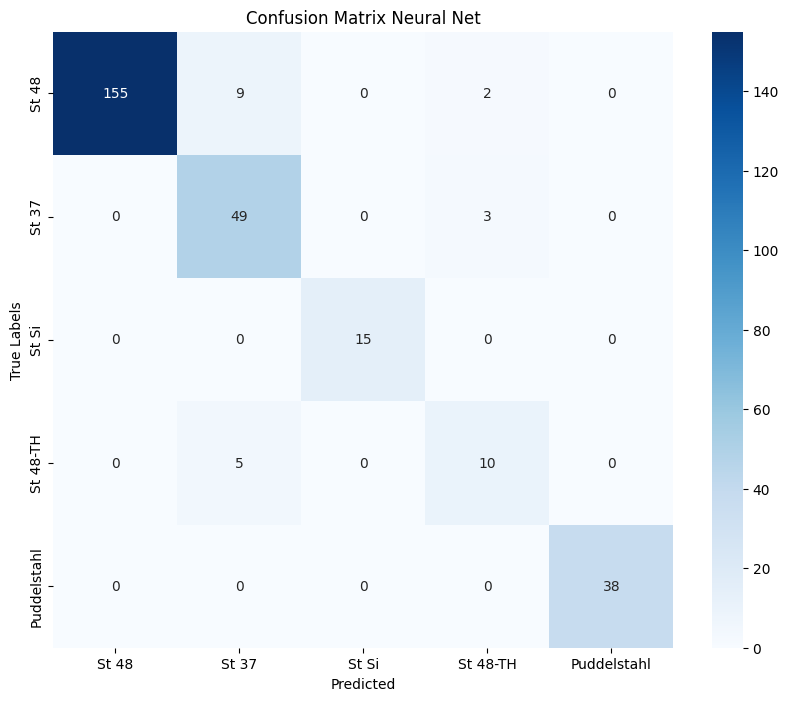

In [32]:
conf_matrix = confusion_matrix(y_test_org, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True Labels')
plt.title('Confusion Matrix Neural Net')
plt.savefig('Confusion_Matrix_NN_Augmented_SMOTE_ENN.jpg', format='jpg')
plt.show()

In [33]:
n_prediction = (model_SMOTE_ENN.predict(previously_misclassified_unlabeled)).argmax(axis=-1)
correct = 0
for i in range(len(n_prediction)):
    print("Prediction: ", n_prediction[i], " - ", "GT: ", previous_label.iloc[i])
    if n_prediction[i] == previous_label.iloc[i]:
        correct += 1
print("In total correct: ", correct)

NameError: name 'previously_misclassified_unlabeled' is not defined

In [34]:
report = classification_report(y_test_org, predicted_classes, target_names=new_labels)
print(report)

              precision    recall  f1-score   support

       St 48       1.00      0.93      0.97       166
       St 37       0.78      0.94      0.85        52
       St Si       1.00      1.00      1.00        15
    St 48-TH       0.67      0.67      0.67        15
 Puddelstahl       1.00      1.00      1.00        38

    accuracy                           0.93       286
   macro avg       0.89      0.91      0.90       286
weighted avg       0.94      0.93      0.94       286

